In [1]:
import scanpy as sc
import matplotlib
import matplotlib.pyplot as plt
import os
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import spearmanr
from Xenium_5K_IPF_constants import WORK_PATH, PUBLIC_PATH

plt.rcParams["font.family"] = "Fira Sans" 
%matplotlib ipympl

REV_PATH=f"{WORK_PATH}Revision/107/"
os.makedirs(REV_PATH, exist_ok=True)

In [2]:
adata_ref = sc.read_h5ad(f"{PUBLIC_PATH}GSE135893/ws/filtered_data.h5ad") 

In [3]:
adata_5k = sc.read_h5ad(f"{WORK_PATH}AnnData/spatial_merged.h5ad")

In [4]:
meta = pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv", index_col="cell_id")

In [5]:
# ===== Settings =====
REF_CT_COL = "celltype"
XEN_CT_COL = "subtype"

REF_TYPES = ["AT1", "AT2", "Transitional AT2", "KRT5-/KRT17+"]
XEN_TYPES = ["AT1", "AT2", "KRT5-/KRT17+"]

In [6]:
adata_5k = adata_5k[meta.index,].copy()
adata_5k.obs = pd.merge(adata_5k.obs, meta[["cell_type_major", "subtype"]], left_index=True, right_index=True)

In [7]:
epi_adata_5k = adata_5k[adata_5k.obs[XEN_CT_COL].isin(XEN_TYPES)].copy()

In [8]:
epi_adata_ref = adata_ref[adata_ref.obs[REF_CT_COL].isin(REF_TYPES)].copy()
sc.pp.filter_genes(epi_adata_ref, min_cells=1)

In [9]:
epi_adata_5k.raw = epi_adata_5k.copy()
sc.pp.normalize_total(epi_adata_5k, target_sum=1e6)
sc.pp.log1p(epi_adata_5k)

epi_adata_ref.raw = epi_adata_ref.copy()
sc.pp.normalize_total(epi_adata_ref, target_sum=1e6)
sc.pp.log1p(epi_adata_ref)

In [10]:
def prepare_adata(
    adata,
    label_col,
):
    A = adata.copy()

    A.obs["cell_type"] = (
        A.obs[label_col]
        .astype(str)
        .str.replace("−", "-", regex=False)
    )

    A.var_names = pd.Index(
        A.var_names.astype(str).str.upper()
    )

    if A.var_names.has_duplicates:
        print(
            "Duplicated gene symbols:",
            A.var_names.duplicated().sum()
        )
        A = A[:, ~A.var_names.duplicated()].copy()

    return A


ref = prepare_adata(
    epi_adata_ref,
    REF_CT_COL,
)

xen = prepare_adata(
    epi_adata_5k,
    XEN_CT_COL,
)

common_genes = sorted(set(ref.var_names) & set(xen.var_names))

print("Reference genes:", ref.n_vars)
print("Xenium genes:", xen.n_vars)
print("Common genes:", len(common_genes))

ref = ref[:, common_genes].copy()
xen = xen[:, common_genes].copy()

Reference genes: 23447
Xenium genes: 5001
Common genes: 4474


In [11]:
def pairwise_deg(adata, target, reference):

    subset = adata[
        adata.obs["cell_type"].isin([target, reference])
    ].copy()

    sc.tl.rank_genes_groups(
        subset,
        groupby="cell_type",
        groups=[target],
        reference=reference,
        method="wilcoxon",
        use_raw=False,
    )

    df = sc.get.rank_genes_groups_df(
        subset,
        group=target,
    )

    return df[["names", "logfoldchanges", "pvals_adj"]].copy()

In [40]:
marker_dict = {
    "AT2": [
        "SFTPC",
        "SFTPB",
        "ABCA3",
        "LAMP3",
        "NAPSA",
        "SLC34A2",
    ],
    "Transitional": [
        "KRT8",
        "CLDN4",
        "KRT19",
        "SFN",
        "GDF15",
        "SOX4",
    ],
    "KRT5-/KRT17+": [
        "KRT17",
        "LAMB3",
        "LAMC2",
        "MMP7",
        "SOX9",
        "ITGB6",
        "CDKN2B",
        "TP63",
    ],
    "AT1": [
        "AGER",
        "CAV1",
        "RTKN2",
        "AQP5",
    ],
}

marker_common = {
    group: [g for g in genes if g in common_genes]
    for group, genes in marker_dict.items()
}

marker_common = {
    group: genes
    for group, genes in marker_common.items()
    if genes
}

for group, genes in marker_common.items():
    print(group, genes)

AT2 ['ABCA3', 'LAMP3']
Transitional ['GDF15']
KRT5-/KRT17+ ['LAMB3', 'LAMC2', 'SOX9', 'ITGB6', 'CDKN2B', 'TP63']
AT1 ['AGER', 'RTKN2', 'AQP5']


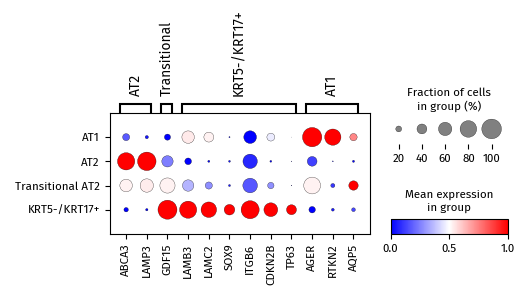

In [45]:
fig, ax = plt.subplots(figsize=(5.3,3))
sc.pl.dotplot(
    ref,
    var_names=marker_common,
    groupby="cell_type",
    categories_order=REF_TYPES,
    standard_scale="var",
    use_raw=False,
    ax=ax,
    show=False,
    cmap="bwr"
)
fig.tight_layout()

fig.savefig(f"{REV_PATH}ref_dotplot.png", dpi=500, format="png", bbox_inches=None)

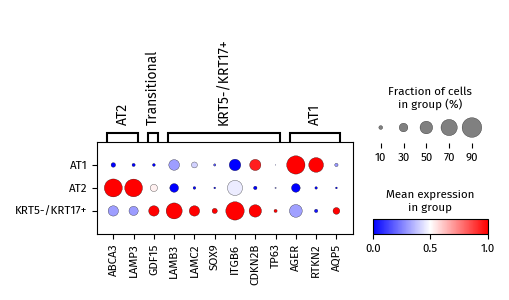

In [47]:

fig, ax = plt.subplots(figsize=(5.1,3))
sc.pl.dotplot(
    xen,
    var_names=marker_common,
    groupby="cell_type",
    categories_order=XEN_TYPES,
    standard_scale="var",
    use_raw=False,
    ax=ax,
    show=False,
    cmap="bwr"
)
fig.tight_layout()

fig.savefig(f"{REV_PATH}xen_dotplot.png", dpi=500, format="png", bbox_inches=None)

In [43]:
def export_dotplot_source(adata, marker_dict, cell_types, output_path):

    genes = list(dict.fromkeys(
        g for group in marker_dict.values() for g in group
    ))

    rows = []

    for ct in cell_types:
        mask = (adata.obs["cell_type"].astype(str) == ct).to_numpy()

        if mask.sum() == 0:
            continue

        X = adata[mask, genes].X

        mean_expr = np.asarray(X.mean(axis=0)).ravel()
        fraction = np.asarray((X > 0).mean(axis=0)).ravel()

        for gene, mean, frac in zip(genes, mean_expr, fraction):
            rows.append({
                "cell_type": ct,
                "gene": gene,
                "mean_expression": mean,
                "fraction_expressing": frac,
                "n_cells": mask.sum(),
            })

    df = pd.DataFrame(rows)

    gene_min = df.groupby("gene")["mean_expression"].transform("min")
    gene_max = df.groupby("gene")["mean_expression"].transform("max")

    denominator = gene_max - gene_min

    df["scaled_mean_expression"] = np.where(
        denominator > 0,
        (df["mean_expression"] - gene_min) /
        denominator.replace(0, np.nan),
        0.0
    )

    gene_groups = [
        {"gene": gene, "marker_group": group}
        for group, genes_in_group in marker_dict.items()
        for gene in genes_in_group
    ]

    df = df.merge(
        pd.DataFrame(gene_groups),
        on="gene",
        how="left"
    )

    df = df[
        [
            "cell_type",
            "marker_group",
            "gene",
            "mean_expression",
            "scaled_mean_expression",
            "fraction_expressing",
            "n_cells",
        ]
    ]

    df.to_csv(output_path, index=False)

    return df

In [44]:
ref_source = export_dotplot_source(
    adata=ref,
    marker_dict=marker_common,
    cell_types=REF_TYPES,
    output_path=f"{REV_PATH}ref_dotplot_source_data.csv"
)

xen_source = export_dotplot_source(
    adata=xen,
    marker_dict=marker_common,
    cell_types=XEN_TYPES,
    output_path=f"{REV_PATH}xen_dotplot_source_data.csv"
)

In [15]:
# Habermann: aberrant basaloid > transitional AT2
deg_ab = pairwise_deg(
    ref,
    "KRT5-/KRT17+",
    "Transitional AT2"
)

# Habermann: transitional AT2 > aberrant basaloid
deg_tr = pairwise_deg(
    ref,
    "Transitional AT2",
    "KRT5-/KRT17+"
)

def select_markers(df, n=15):
    return (
        df.loc[
            (df["pvals_adj"] < 0.05) &
            (df["logfoldchanges"] > 0.5)
        ]
        .sort_values("logfoldchanges", ascending=False)
        ["names"]
        .head(n)
        .tolist()
    )

markers = {
    "Transitional AT2 > Aberrant": select_markers(deg_tr),
    "Aberrant > Transitional AT2": select_markers(deg_ab)
}

for group, genes in markers.items():
    print(group, len(genes))
    print(genes)

Transitional AT2 > Aberrant 15
['CLDN18', 'CCDC141', 'SLC39A8', 'LAMP3', 'AGER', 'PEBP4', 'LRRK2', 'AQP4', 'SELENBP1', 'ABCA3', 'HSD17B6', 'SULT1A1', 'HK2', 'COLEC12', 'AQP5']
Aberrant > Transitional AT2 15
['SMOC1', 'HMGA2', 'HNF4A', 'FST', 'CA9', 'PLAU', 'CDH2', 'CDKN2A', 'FHL2', 'TNC', 'TUBB2B', 'TP63', 'COL7A1', 'PTHLH', 'FRMD6']


In [16]:
genes = list(dict.fromkeys(
    markers["Transitional AT2 > Aberrant"] +
    markers["Aberrant > Transitional AT2"]
))

def group_expression(adata, genes):
    results = []

    for ct in adata.obs["cell_type"].unique():
        a = adata[
            adata.obs["cell_type"] == ct,
            genes
        ]

        X = a.X

        mean_expr = np.asarray(X.mean(axis=0)).ravel()

        pct = np.asarray((X > 0).mean(axis=0)).ravel()

        for gene, m, p in zip(genes, mean_expr, pct):
            results.append({
                "cell_type": ct,
                "gene": gene,
                "mean_expression": m,
                "pct_expression": p,
            })

    return pd.DataFrame(results)


ref_expr = group_expression(ref, genes)
xen_expr = group_expression(xen, genes)

def expression_difference(df, group1, group2):
    mat = df.pivot(
        index="gene",
        columns="cell_type",
        values="mean_expression"
    )
    return mat[group1] - mat[group2]


delta_ref = expression_difference(
    ref_expr,
    "Transitional AT2",
    "KRT5-/KRT17+"
)

delta_xen = expression_difference(
    xen_expr,
    "AT2",
    "KRT5-/KRT17+"
)

comparison = pd.DataFrame({
    "Reference_delta": delta_ref,
    "Xenium_delta": delta_xen,
})

comparison["signature"] = [
    "Transitional AT2"
    if gene in markers["Transitional AT2 > Aberrant"]
    else "Aberrant basaloid"
    for gene in comparison.index
]

comparison["same_direction"] = (
    np.sign(comparison["Reference_delta"]) ==
    np.sign(comparison["Xenium_delta"])
)

rho, p = spearmanr(
    comparison["Reference_delta"],
    comparison["Xenium_delta"]
)

print(f"Spearman rho: {rho:.3f}")
print(
    "Direction concordance:",
    f"{comparison['same_direction'].mean():.1%}"
)

Spearman rho: 0.531
Direction concordance: 90.0%


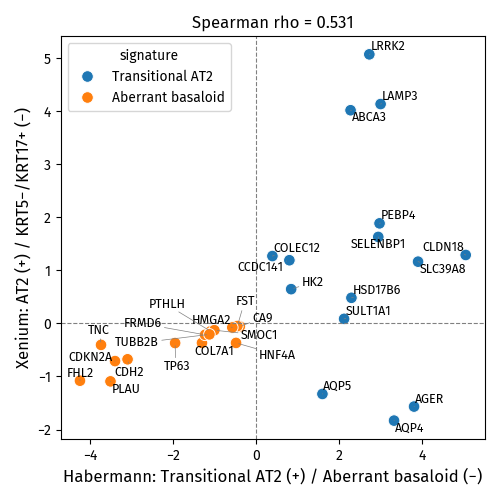

In [36]:
from adjustText import adjust_text

fig, ax = plt.subplots(figsize=(5, 5))

sns.scatterplot(
    data=comparison,
    x="Reference_delta",
    y="Xenium_delta",
    hue="signature",
    s=70,
    ax=ax
)

ax.axhline(0, color="gray", ls="--", lw=0.8)
ax.axvline(0, color="gray", ls="--", lw=0.8)

# 遺伝子名をリストに格納
texts = []

for gene, row in comparison.iterrows():
    texts.append(
        ax.text(
            row["Reference_delta"],
            row["Xenium_delta"],
            gene,
            fontsize=9,
        )
    )

# 遺伝子名の重なりを調整
adjust_text(
    texts,
    ax=ax,
    x=comparison["Reference_delta"].values,
    y=comparison["Xenium_delta"].values,
    force_text=(0.5, 0.5),
    arrowprops=dict(
        arrowstyle="-",
        color="gray",
        lw=0.5,
    ),
)

ax.set_xlabel(
    "Habermann: Transitional AT2 (+) / Aberrant basaloid (−)", fontsize=12
)
ax.set_ylabel(
    "Xenium: AT2 (+) / KRT5−/KRT17+ (−)", fontsize=12
)

ax.set_title(f"Spearman rho = {rho:.3f}")

plt.tight_layout()

fig.savefig(
    f"{REV_PATH}signature_scatter.png",
    dpi=500,
    format="png",
    bbox_inches="tight"
)

In [22]:
# Source data for signature scatter plot

scatter_source = comparison.copy().reset_index()

scatter_source = scatter_source.rename(
    columns={"index": "gene"}
)

scatter_source["direction_concordant"] = (
    np.sign(scatter_source["Reference_delta"]) ==
    np.sign(scatter_source["Xenium_delta"])
)

scatter_source = scatter_source[
    [
        "gene",
        "signature",
        "Reference_delta",
        "Xenium_delta",
        "direction_concordant",
    ]
]

scatter_source.to_csv(
    f"{REV_PATH}signature_scatter_source_data.csv",
    index=False
)

,gene,signature,Reference_delta,Xenium_delta,direction_concordant
0,ABCA3,Transitional AT2,2.281758,4.015855,True
1,AGER,Transitional AT2,3.811918,-1.566545,False
2,AQP4,Transitional AT2,3.329875,-1.831252,False
3,AQP5,Transitional AT2,1.603877,-1.329359,False
4,CA9,Aberrant basaloid,-0.385614,-0.056419,True
5,CCDC141,Transitional AT2,0.807509,1.190164,True
6,CDH2,Aberrant basaloid,-3.092494,-0.676320,True
7,CDKN2A,Aberrant basaloid,-3.394253,-0.709887,True
8,CLDN18,Transitional AT2,5.056975,1.288943,True
9,COL7A1,Aberrant basaloid,-1.299085,-0.367177,True
